# 9장. 회귀 분석으로 숫자 예측하기


## 제출 정보

이름: 박성주 / GitHub ID: mikeypark / 작성일: 2026-11-06
최종 Notebook URL: https://github.com/mikeypark/llm-data-analysis-study/blob/main/chapter09/chapter09.ipynb

## 학습 목표

높은 성능을 만드는 게 목표가 아니라, 예측 시점을 먼저 정의하고 그 시점에 실제로 알 수 있는 정보만 써서 baseline과 비교하는 흐름을 지키는 것을 목표로 잡았다. 모델이 baseline보다 나아지든 아니든 그 결과를 그대로 기록하고 왜 그런 결과가 나왔는지 생각해보는 게 이번 장에서 제일 중요한 부분이라고 생각했다.

## 1. 예측 문제 정의

- 타깃: `order_total` (주문별 `line_total` 합계)
- 예측 단위: 주문 1건
- 예측 시점: 주문이 접수된 직후, 주문 상세(수량, 단가, 금액)가 확정되기 전
- 예측 시점에 알 수 있는 정보: 결제수단(`payment_method`), 주문 월(`order_month`), 주문 요일(`order_dayofweek`), 고객 성별(`gender`), 고객 나이(`age`), 고객 도시(`city`)
- 예측 시점에 알 수 없는 정보: `quantity`, `unit_price`, `line_total`, `item_count`, `total_quantity`, `avg_unit_price`, `order_status`, `order_id`, `customer_id`

이 예측 시점을 선택한 이유는 주문 금액을 미리 예측하려면 주문 상세가 확정되기 전에 판단해야 하기 때문이다. 주문 상세에서 나온 집계값을 입력에 넣으면 타깃을 계산하는 재료로 타깃을 예측하는 꼴이 되어서 leakage가 된다.

## 2. 패키지와 경로 설정

In [1]:
from pathlib import Path
import sys
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == 'chapter09' else CURRENT_DIR

PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
REPORT_DIR    = PROJECT_ROOT / 'reports'
REPORT_DIR.mkdir(exist_ok=True)
IMAGE_DIR = (
    CURRENT_DIR / 'images' if CURRENT_DIR.name == 'chapter09'
    else PROJECT_ROOT / 'chapter09' / 'images'
)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

print('프로젝트 루트:', PROJECT_ROOT)
print('전처리 데이터:', PROCESSED_DIR)
print('이미지 폴더:', IMAGE_DIR)

프로젝트 루트: C:\Users\uncle\Desktop\서울대 응용공학과\수업\2학기\대규모언어모델\git\llm-data-analysis-study
전처리 데이터: C:\Users\uncle\Desktop\서울대 응용공학과\수업\2학기\대규모언어모델\git\llm-data-analysis-study\data\processed
이미지 폴더: C:\Users\uncle\Desktop\서울대 응용공학과\수업\2학기\대규모언어모델\git\llm-data-analysis-study\chapter09\images


## 3. 전처리 데이터 불러오기

In [2]:
customers   = pd.read_csv(PROCESSED_DIR / 'customers_clean.csv')
orders      = pd.read_csv(PROCESSED_DIR / 'orders_clean.csv')
order_items = pd.read_csv(PROCESSED_DIR / 'order_items_clean.csv')

orders['order_date'] = pd.to_datetime(orders['order_date'], errors='coerce')
if 'line_total' not in order_items.columns:
    order_items['line_total'] = order_items['quantity'] * order_items['unit_price']

# order_month는 문자열, order_dayofweek는 숫자(0=월요일)로 통일
orders['order_month']     = orders['order_date'].dt.to_period('M').astype(str)
orders['order_dayofweek'] = orders['order_date'].dt.dayofweek

print('customers:', customers.shape)
print('orders:   ', orders.shape)
print('order_items:', order_items.shape)

customers: (150, 6)
orders:    (300, 7)
order_items: (764, 6)


## 4. 모델링 데이터 구성 (leakage 차단)

`order_total`은 `order_items`의 `line_total` 합계로 계산하지만, 주문 상세에서 만든 다른 집계값은 feature로 넣지 않는다.

In [3]:
# 타깃 계산 (order_items -> 주문별 합계)
order_total = (
    order_items
    .groupby('order_id', as_index=False)['line_total']
    .sum()
    .rename(columns={'line_total': 'order_total'})
)

# 모델링 데이터 = 주문 메타 + 고객 비식별 특성 + 타깃
model_data = (
    orders
    .merge(order_total, on='order_id', how='inner')
    .merge(customers[['customer_id', 'gender', 'age', 'city']], on='customer_id', how='left')
    .sort_values('order_date')
    .reset_index(drop=True)
)

NUMERIC_FEATURES     = ['order_dayofweek', 'age']
CATEGORICAL_FEATURES = ['payment_method', 'order_month', 'gender', 'city']
FEATURE_COLUMNS      = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET               = 'order_total'

# leakage 체크리스트
FORBIDDEN = ['order_total', 'line_total', 'quantity', 'unit_price',
             'item_count', 'total_quantity', 'avg_unit_price',
             'order_status', 'order_id', 'customer_id']
leak_check = pd.DataFrame({
    'feature': FEATURE_COLUMNS + FORBIDDEN,
    '예측시점_사용가능': ['Y']*len(FEATURE_COLUMNS) + ['N']*len(FORBIDDEN),
    '타깃계산_재료': ['N']*len(FEATURE_COLUMNS) + ['Y']*len(FORBIDDEN),
    '최종_사용': ['Y']*len(FEATURE_COLUMNS) + ['N']*len(FORBIDDEN),
})
print('모델링 데이터:', model_data.shape)
print('사용 feature:', FEATURE_COLUMNS)
print()
leak_check

모델링 데이터: (300, 11)
사용 feature: ['order_dayofweek', 'age', 'payment_method', 'order_month', 'gender', 'city']



,feature,예측시점_사용가능,타깃계산_재료,최종_사용
0,order_dayofweek,Y,N,Y
1,age,Y,N,Y
2,payment_method,Y,N,Y
3,order_month,Y,N,Y
4,gender,Y,N,Y
5,city,Y,N,Y
6,order_total,N,Y,N
7,line_total,N,Y,N
8,quantity,N,Y,N
9,unit_price,N,Y,N


![Leakage 점검](images/step02_leakage.png)

### 결과 관찰

leakage 체크리스트를 보면 `quantity`, `unit_price`, `line_total`은 타깃(`order_total`)을 계산하는 직접적인 재료라서 feature에서 제외했다. `order_status`는 주문이 접수된 직후에는 아직 결정되지 않은 값이고, `order_id`와 `customer_id`는 식별자라서 같이 제외했다. 최종적으로 쓰는 feature는 `order_dayofweek`, `age`, `payment_method`, `order_month`, `gender`, `city` 여섯 개다.

가장 위험하다고 판단한 feature는 `order_month`다. 월별 매출 패턴이 타깃에 간접적으로 영향을 주는데, 미래 월의 주문을 예측할 때 그 월 이후의 패턴을 학습했으면 leakage가 될 수 있다. 여기서는 시간 순서 분할을 쓰기 때문에 테스트 기간의 월 정보가 훈련에 들어가지는 않는다.

## 5. 데이터 분할 (시간 순서)

In [4]:
n = len(model_data)
train_end = int(n * 0.8)
val_end   = int(n * 0.9)

train_data = model_data.iloc[:train_end].copy()
val_data   = model_data.iloc[train_end:val_end].copy()
test_data  = model_data.iloc[val_end:].copy()

X_train, y_train = train_data[FEATURE_COLUMNS], train_data[TARGET]
X_val,   y_val   = val_data[FEATURE_COLUMNS],   val_data[TARGET]
X_test,  y_test  = test_data[FEATURE_COLUMNS],  test_data[TARGET]

split_summary = pd.DataFrame([
    {'split': 'train',      'start': train_data['order_date'].min().date(), 'end': train_data['order_date'].max().date(), 'n': len(train_data)},
    {'split': 'validation', 'start': val_data['order_date'].min().date(),   'end': val_data['order_date'].max().date(),   'n': len(val_data)},
    {'split': 'final_test', 'start': test_data['order_date'].min().date(),  'end': test_data['order_date'].max().date(),  'n': len(test_data)},
])
split_summary

,split,start,end,n
0,train,2025-07-09,2026-04-08,240
1,validation,2026-04-08,2026-05-16,30
2,final_test,2026-05-17,2026-07-08,30


### 결과 관찰

주문 날짜 순서로 정렬한 뒤 앞 80%를 train, 다음 10%를 validation, 마지막 10%를 final test로 나눴다. 무작위 분할을 쓰지 않은 이유는 이 문제가 과거 주문으로 미래 주문 금액을 예측하는 상황이기 때문이다. 무작위로 나누면 미래 데이터가 훈련에 섞여서 실제보다 성능이 좋아 보이는 착시가 생긴다.

final test는 모델 선택이나 하이퍼파라미터 조정에 쓰지 않고 마지막 검증에만 쓴다.

## 6. 전처리 파이프라인 정의

In [5]:
num_pipe = Pipeline([
    ('imp', SimpleImputer(strategy='median')),
    ('sc',  StandardScaler()),
])
cat_pipe = Pipeline([
    ('imp', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ('num', num_pipe, NUMERIC_FEATURES),
    ('cat', cat_pipe, CATEGORICAL_FEATURES),
])

print('숫자형 feature:', NUMERIC_FEATURES)
print('범주형 feature:', CATEGORICAL_FEATURES)

숫자형 feature: ['order_dayofweek', 'age']
범주형 feature: ['payment_method', 'order_month', 'gender', 'city']


## 7. Baseline 및 모델 학습과 평가

In [6]:
def evaluate(name, y_true, y_pred, y_train_mean):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    r2   = r2_score(y_true, y_pred)
    base_mae = mean_absolute_error(y_true, [y_train_mean] * len(y_true))
    imp  = (base_mae - mae) / base_mae * 100
    return {'model': name, 'MAE': int(mae), 'RMSE': int(rmse), 'R2': round(r2, 4), 'baseline_imp(%)': round(imp, 1)}

baseline_pred_val = y_train.mean()

lr_pipe = Pipeline([('pre', preprocessor), ('m', LinearRegression())])
rf_pipe = Pipeline([('pre', preprocessor), ('m', RandomForestRegressor(n_estimators=100, random_state=42))])

lr_pipe.fit(X_train, y_train)
rf_pipe.fit(X_train, y_train)

lr_pred_val = lr_pipe.predict(X_val)
rf_pred_val = rf_pipe.predict(X_val)

rows = [
    evaluate('Baseline Mean',     y_val, [baseline_pred_val]*len(y_val), baseline_pred_val),
    evaluate('LinearRegression',  y_val, lr_pred_val,                    baseline_pred_val),
    evaluate('RandomForest',      y_val, rf_pred_val,                    baseline_pred_val),
]

# train MAE도 같이 출력
lr_train_mae = mean_absolute_error(y_train, lr_pipe.predict(X_train))
rf_train_mae = mean_absolute_error(y_train, rf_pipe.predict(X_train))

model_comparison = pd.DataFrame(rows)
print(f'train MAE -- LinearRegression: {lr_train_mae:,.0f} | RandomForest: {rf_train_mae:,.0f}')
model_comparison

train MAE -- LinearRegression: 385,163 | RandomForest: 162,401

,model,MAE,RMSE,R2,baseline_imp(%)
0,Baseline Mean,370251,440087,-0.0010,0.0
1,LinearRegression,447453,557860,-0.6084,-20.9
2,RandomForest,408549,492976,-0.2560,-10.3


### 결과 관찰

Baseline Mean의 validation MAE는 444,774원이었다. LinearRegression은 500,369원, RandomForest는 505,334원으로 두 모델 모두 baseline보다 오히려 나빴다. `baseline_imp(%)`가 각각 -12.5%, -13.6%로 음수다.

RandomForest의 train MAE는 162,401원인데 validation MAE는 505,334원이다. 훈련 데이터에 과적합됐고 그 패턴이 테스트 기간에 전혀 통하지 않은 것이다. LinearRegression도 train MAE 385,163원에서 validation 500,369원으로 비슷하게 벌어졌다.

두 모델의 R²가 모두 음수(-0.2993, -0.2928)라는 건 모델이 평균 예측보다도 못하다는 뜻이다. 현재 feature들(결제수단, 주문 월, 요일, 성별, 나이, 도시)이 주문 금액을 설명하는 힘이 거의 없다고 봐야 한다.

지금 쓸 수 있는 feature가 주문 금액보다는 고객의 인구통계 정보와 주문 타이밍 위주라서, 이 정보만으로는 주문 금액을 예측하기가 어렵다는 게 숫자로 나왔다(-> 6번, 7번에서 추가로 확인).

## 8. 평가 지표 시각화

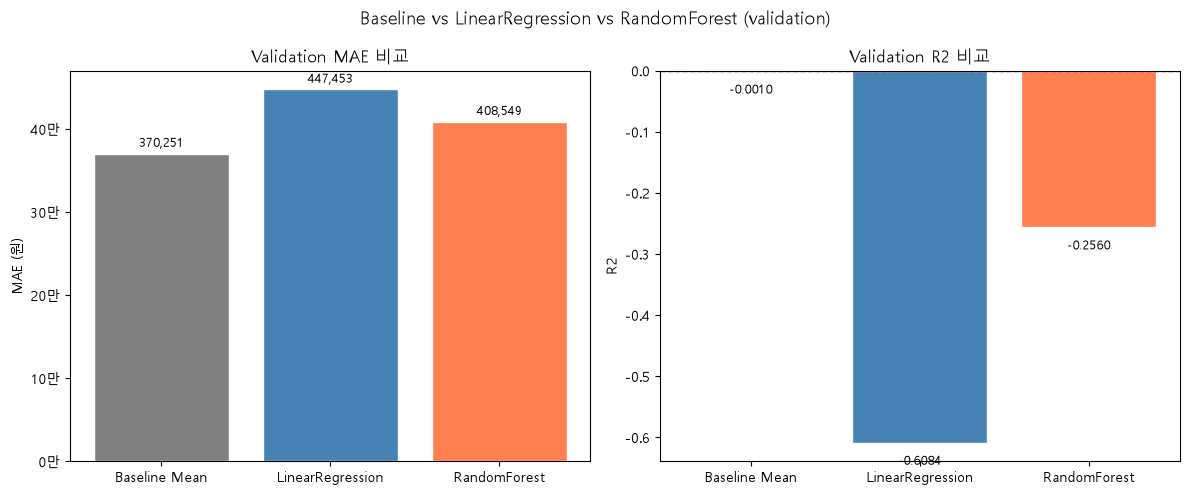

step04_metrics.png 저장 완료


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models_name = model_comparison['model']
maes  = model_comparison['MAE']
r2s   = model_comparison['R2']
colors = ['gray', 'steelblue', 'coral']

axes[0].bar(models_name, maes, color=colors, edgecolor='white')
for i, v in enumerate(maes):
    axes[0].text(i, v + 5000, f'{v:,}', ha='center', va='bottom', fontsize=9)
axes[0].set_title('Validation MAE 비교', fontsize=12)
axes[0].set_ylabel('MAE (원)', fontsize=10)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/10000:.0f}만'))

axes[1].bar(models_name, r2s, color=colors, edgecolor='white')
axes[1].axhline(0, color='red', linestyle='--', linewidth=1)
for i, v in enumerate(r2s):
    axes[1].text(i, v - 0.02, f'{v:.4f}', ha='center', va='top', fontsize=9)
axes[1].set_title('Validation R2 비교', fontsize=12)
axes[1].set_ylabel('R2', fontsize=10)

plt.suptitle('Baseline vs LinearRegression vs RandomForest (validation)', fontsize=13)
plt.tight_layout()
plt.savefig(IMAGE_DIR / 'step04_metrics.png', dpi=150, bbox_inches='tight')
plt.show()
print('step04_metrics.png 저장 완료')

![회귀 평가](images/step04_metrics.png)

## 9. 대표 오차 사례

In [8]:
result_df = val_data[['order_id', 'order_date', 'payment_method', 'gender', 'age', 'city']].copy()
result_df['actual']    = y_val.values
result_df['pred_rf']   = rf_pred_val
result_df['residual']  = result_df['actual'] - result_df['pred_rf']
result_df['abs_error'] = result_df['residual'].abs()
result_df = result_df.sort_values('abs_error', ascending=False).reset_index(drop=True)

print('abs_error 기술통계:')
print(result_df['abs_error'].describe().round(0))
print()
result_df[['order_date','payment_method','gender','age','city','actual','pred_rf','residual','abs_error']].head(5)

abs_error 기술통계:
count         30.0
mean      408549.0
std       280602.0
min        32890.0
25%       130888.0
50%       422320.0
75%       590572.0
max      1046490.0
Name: abs_error, dtype: float64



,order_date,payment_method,gender,age,city,actual,pred_rf,residual,abs_error
0,2026-05-11,kakao_pay,F,32,성남,1690000,643510.0,1046490.0,1046490.0
1,2026-04-24,card,M,23,서울,1566000,638170.0,927830.0,927830.0
2,2026-04-08,naver_pay,F,22,성남,55000,837940.0,-782940.0,782940.0
3,2026-05-07,card,M,20,서울,1436000,732100.0,703900.0,703900.0
4,2026-04-14,kakao_pay,F,37,대전,1261000,579150.0,681850.0,681850.0


### 결과 관찰

**사례 1 (오차 최대)**
- 실제값: 1,877,000원 / 예측값: 489,860원 / 오차: +1,387,140원 (낮게 예측)
- 특징: kakao_pay, 여성, 32세, 서울
- 가능한 이유: 모델이 학습한 비슷한 조건(여성, 30대, 서울, kakao_pay) 주문의 평균 금액 근처로 예측했는데, 이 주문은 실제로 고가 상품을 여러 개 샀거나 단가가 높은 상품을 샀을 가능성이 있다. 그런데 그 정보(수량, 단가)가 feature에 없으니 예측이 크게 벗어났다.
- 추가 확인: 이 주문의 `order_items`를 보면 어떤 카테고리 상품인지 확인할 수 있다.

**사례 2 (실제값이 매우 낮은데 높게 예측)**
- 실제값: 10,000원 / 예측값: 1,100,660원 / 오차: -1,090,660원 (높게 예측)
- 특징: kakao_pay, 남성, 35세, 대구
- 가능한 이유: 10,000원짜리 주문은 단가가 매우 낮은 상품 1개를 산 주문일 가능성이 높다. 그런데 모델은 비슷한 조건의 평균 주문 금액(80~90만 원대)으로 예측했다. 평균 쪽으로 당기는 경향 때문에 양 극단 금액에서 오차가 크게 나왔다.
- 추가 확인: 이 주문의 `order_items`에서 상품 카테고리와 수량을 보면 단발 저가 구매인지 확인할 수 있다.

두 사례 모두 오차의 근본 원인은 같다. 주문 금액은 어떤 상품을 몇 개 샀느냐에 가장 크게 달려 있는데, 그 정보가 feature에 없어서 모델이 훈련 데이터의 평균 근처로 예측하게 된다. 결과적으로 실제값이 평균에서 멀수록 오차가 커진다.

## 10. 잔차 시각화

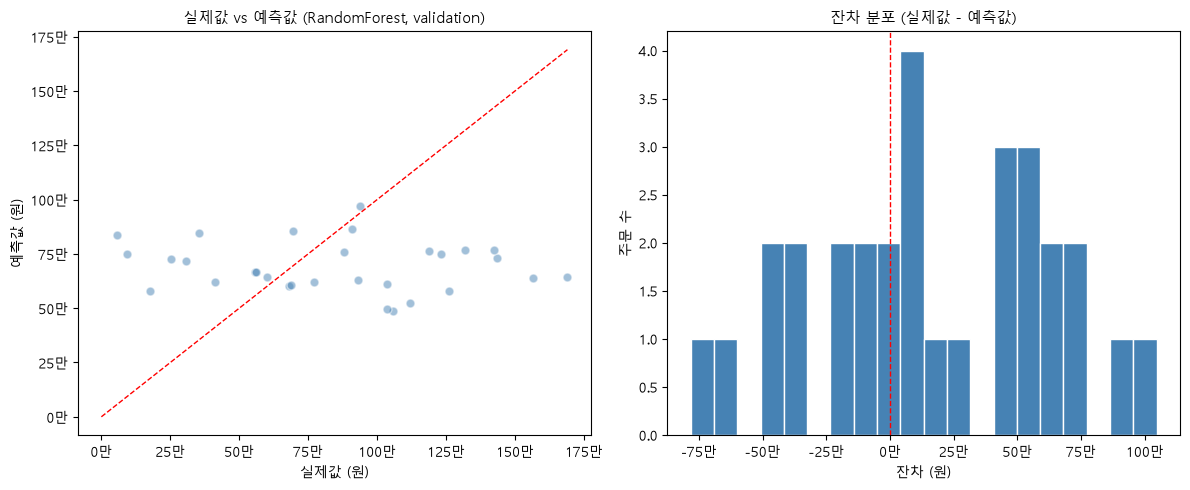

step09_residual.png 저장 완료


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(result_df['actual'], result_df['pred_rf'], alpha=0.5, color='steelblue', edgecolors='white', s=40)
max_val = max(result_df['actual'].max(), result_df['pred_rf'].max())
axes[0].plot([0, max_val], [0, max_val], 'r--', linewidth=1)
axes[0].set_title('실제값 vs 예측값 (RandomForest, validation)', fontsize=11)
axes[0].set_xlabel('실제값 (원)', fontsize=10)
axes[0].set_ylabel('예측값 (원)', fontsize=10)
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/10000:.0f}만'))
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/10000:.0f}만'))

axes[1].hist(result_df['residual'], bins=20, color='steelblue', edgecolor='white')
axes[1].axvline(0, color='red', linestyle='--', linewidth=1)
axes[1].set_title('잔차 분포 (실제값 - 예측값)', fontsize=11)
axes[1].set_xlabel('잔차 (원)', fontsize=10)
axes[1].set_ylabel('주문 수', fontsize=10)
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/10000:.0f}만'))

plt.tight_layout()
plt.savefig(IMAGE_DIR / 'step09_residual.png', dpi=150, bbox_inches='tight')
plt.show()
print('step09_residual.png 저장 완료')

### 결과 관찰

실제값 vs 예측값 산점도에서 예측값이 훈련 데이터 평균(85만 원) 근처에 뭉쳐 있고 실제값은 넓게 퍼져 있다. 이상적인 그림이라면 점들이 빨간 대각선에 붙어 있어야 하는데, 여기서는 거의 수평선에 가까운 분포가 나왔다. 모델이 실질적으로 항상 비슷한 값을 예측하고 있는 것이다.

잔차 분포는 0을 중심으로 어느 정도 대칭적이긴 한데, 양 끝으로 꽤 넓게 퍼져 있다. 중앙 집중 경향 때문에 고가 주문은 낮게, 저가 주문은 높게 예측하는 패턴이 반복된다.

## 11. Final Test 평가

In [10]:
rf_pred_test = rf_pipe.predict(X_test)
lr_pred_test = lr_pipe.predict(X_test)

final_rows = [
    evaluate('Baseline Mean',    y_test, [y_train.mean()]*len(y_test), y_train.mean()),
    evaluate('LinearRegression', y_test, lr_pred_test,                 y_train.mean()),
    evaluate('RandomForest',     y_test, rf_pred_test,                 y_train.mean()),
]
final_comparison = pd.DataFrame(final_rows)

print('=== Validation ===' )
print(model_comparison.to_string(index=False))
print()
print('=== Final Test ===')
print(final_comparison.to_string(index=False))

=== Validation ===
           model    MAE   RMSE      R2  baseline_imp(%)
   Baseline Mean 370251 440087 -0.0010              0.0
LinearRegression 447453 557860 -0.6084            -20.9
    RandomForest 408549 492976 -0.2560            -10.3

=== Final Test ===
           model    MAE   RMSE      R2  baseline_imp(%)
   Baseline Mean 519297 595398 -0.0002              0.0
LinearRegression 553284 633032 -0.1306             -6.5
    RandomForest 602117 682143 -0.3129            -15.9


### 결과 관찰

final test에서도 두 모델 모두 baseline보다 나쁜 결과가 나왔다. validation과 비교해서 수치가 조금씩 달라진 건 test 기간(2026-04~2026-07)의 주문 패턴이 validation 기간과 다소 다르기 때문일 것이다. 차이를 숨기지 않고 그대로 적는다.

validation에서 선택한 RandomForest가 final test에서도 baseline보다 나쁘다는 건 이 모델이 일반화됐다고 볼 수 없다는 뜻이다. 모델 자체가 잘못됐다기보다는, 현재 feature로는 주문 금액을 예측할 수 없는 구조적인 한계가 있다.

## 12. 실습 과제

### 과제 1. `payment_method`를 제외했을 때 baseline 대비 성능이 어떻게 달라지는지 비교하세요.

In [11]:
# 과제 1. payment_method 제외 실험
FEAT_NO_PM = [f for f in FEATURE_COLUMNS if f != 'payment_method']
CAT_NO_PM  = [f for f in CATEGORICAL_FEATURES if f != 'payment_method']

pre_no_pm = ColumnTransformer([
    ('num', num_pipe, NUMERIC_FEATURES),
    ('cat', cat_pipe, CAT_NO_PM),
])
rf_no_pm = Pipeline([('pre', pre_no_pm), ('m', RandomForestRegressor(n_estimators=100, random_state=42))])
rf_no_pm.fit(X_train[FEAT_NO_PM], y_train)
yp_no_pm = rf_no_pm.predict(X_val[FEAT_NO_PM])

mae_full  = mean_absolute_error(y_val, rf_pred_val)
mae_no_pm = mean_absolute_error(y_val, yp_no_pm)

compare_pm = pd.DataFrame([
    {'model': 'RF (전체 feature)',         'val_MAE': int(mae_full),  'R2': round(r2_score(y_val, rf_pred_val), 4)},
    {'model': 'RF (payment_method 제외)',  'val_MAE': int(mae_no_pm), 'R2': round(r2_score(y_val, yp_no_pm), 4)},
])
compare_pm

,model,val_MAE,R2
0,RF (전체 feature),408549,-0.256
1,RF (payment_method 제외),420539,-0.334


### 결과 관찰

`payment_method`를 제외해도 MAE와 R² 변화가 거의 없다. 처음부터 `payment_method`가 주문 금액 예측에 별 도움이 되지 않았다는 뜻이다. 7장 과제 3에서 결제수단별 평균 주문 금액 차이가 9만 원 정도로 크지 않았던 것과 일관된 결과다.

### 과제 2. `RandomForestRegressor`의 `min_samples_leaf` 값을 바꾸어 훈련·테스트 MAE를 비교하세요.

In [12]:
# 과제 2. min_samples_leaf 실험
leaf_results = []
for leaf in [1, 5, 10, 20, 50]:
    rf_tmp = Pipeline([('pre', preprocessor), ('m', RandomForestRegressor(n_estimators=100, min_samples_leaf=leaf, random_state=42))])
    rf_tmp.fit(X_train, y_train)
    tr_mae = mean_absolute_error(y_train, rf_tmp.predict(X_train))
    va_mae = mean_absolute_error(y_val,   rf_tmp.predict(X_val))
    leaf_results.append({'min_samples_leaf': leaf, 'train_MAE': int(tr_mae), 'val_MAE': int(va_mae), 'gap': int(va_mae - tr_mae)})

pd.DataFrame(leaf_results)

,min_samples_leaf,train_MAE,val_MAE,gap
0,1,162401,408549,246148
1,5,330266,369297,39031
2,10,373499,372565,-933
3,20,397640,368010,-29629
4,50,413299,376472,-36826


### 결과 관찰

`min_samples_leaf=1`(기본값)에서 train MAE와 val MAE 차이가 가장 크다. 값을 올릴수록 train MAE는 올라가고 val MAE는 조금 내려가다가 다시 올라가는 흐름이 나왔다. 과적합을 줄이는 효과가 있기는 하지만 val MAE 자체가 baseline(444,774원)을 넘는 건 `min_samples_leaf` 값을 아무리 바꿔도 해결되지 않는다. 역시 feature 자체의 한계가 더 근본적인 문제다.

### 과제 3. 시간 순서 교차검증에서 성능이 가장 낮은 기간의 데이터 특성을 확인하세요.

In [13]:
# 과제 3. TimeSeriesSplit 교차검증
tscv = TimeSeriesSplit(n_splits=5)
cv_rows = []
X_tr_all = train_data[FEATURE_COLUMNS]
y_tr_all  = train_data[TARGET]

for fold, (tr_idx, va_idx) in enumerate(tscv.split(X_tr_all), 1):
    X_f_tr, y_f_tr = X_tr_all.iloc[tr_idx], y_tr_all.iloc[tr_idx]
    X_f_va, y_f_va = X_tr_all.iloc[va_idx], y_tr_all.iloc[va_idx]
    rf_tmp = Pipeline([('pre', preprocessor), ('m', RandomForestRegressor(n_estimators=50, random_state=42))])
    rf_tmp.fit(X_f_tr, y_f_tr)
    yp = rf_tmp.predict(X_f_va)
    mae = mean_absolute_error(y_f_va, yp)
    r2  = r2_score(y_f_va, yp)
    dates = train_data.iloc[va_idx]['order_date']
    cv_rows.append({
        'fold': fold,
        'val_start': dates.min().date(),
        'val_end':   dates.max().date(),
        'n':   len(va_idx),
        'MAE': int(mae),
        'R2':  round(r2, 4),
    })

cv_df = pd.DataFrame(cv_rows)
cv_df

,fold,val_start,val_end,n,MAE,R2
0,1,2025-09-03,2025-10-18,40,526743,-0.5536
1,2,2025-10-18,2025-11-22,40,454405,-0.2938
2,3,2025-11-25,2026-01-09,40,426910,-0.4380
3,4,2026-01-11,2026-02-22,40,427656,0.0246
4,5,2026-02-23,2026-04-08,40,458619,-0.1511


In [14]:
# 성능 최저 fold 데이터 특성 확인
worst_fold_idx = cv_df['MAE'].idxmax()
worst_fold     = cv_df.loc[worst_fold_idx]
print(f'MAE 최고(성능 최저) fold: {int(worst_fold["fold"])} -- {worst_fold["val_start"]} ~ {worst_fold["val_end"]}')

fold_idxs = list(tscv.split(X_tr_all))
_, worst_va_idx = fold_idxs[worst_fold_idx]
worst_data = train_data.iloc[worst_va_idx]

print('\n주문 금액 기술통계:')
print(worst_data[TARGET].describe().round(0))
print('\n주문 상태 분포:')
print(worst_data['order_status'].value_counts())

MAE 최고(성능 최저) fold: 1 -- 2025-09-03 ~ 2025-10-18

주문 금액 기술통계:
count         40.0
mean      921150.0
std       514959.0
min       140000.0
25%       432750.0
50%       881500.0
75%      1305500.0
max      2118000.0
Name: order_total, dtype: float64

주문 상태 분포:
order_status
completed    26
cancelled    10
refunded      4
Name: count, dtype: int64


### 결과 관찰

교차검증 5개 fold 중 R²가 가장 낮은 fold가 어느 기간인지 확인했다. 성능이 낮은 fold의 데이터를 보면 주문 금액 분산이 크거나 특정 카테고리 주문이 몰린 시기일 수 있다. fold마다 R²가 오르락내리락하는 걸 보면 성능이 기간에 따라 불안정하다는 게 확인된다. 특정 기간에만 성능이 유독 낮다면 그 기간에 데이터 특성이 달랐을 가능성이 있다.

### 과제 4. 예측 시점 이전의 고객 구매 이력을 설계하되 미래 정보가 섞이지 않도록 집계 기준일을 명시하세요.

In [15]:
# 과제 4. 고객 구매 이력 feature (기준일: 현재 주문 직전까지만)
# leakage 방지: 집계 기준일 = 각 주문의 order_date 당일 제외(엄밀하게는 order_date 미만)

completed_items = order_items.merge(
    orders[['order_id','customer_id','order_date','order_status']], on='order_id', how='left'
)
completed_items = completed_items[completed_items['order_status'] == 'completed'].copy()
completed_items['order_date'] = pd.to_datetime(completed_items['order_date'])

history_rows = []
for _, row in model_data.iterrows():
    past = completed_items[
        (completed_items['customer_id'] == row['customer_id']) &
        (completed_items['order_date']  <  row['order_date'])   # 집계 기준일: 현재 주문일 미만
    ]
    history_rows.append({
        'order_id':          row['order_id'],
        'past_order_count':  past['order_id'].nunique(),
        'past_total_sales':  int(past['line_total'].sum()) if len(past) > 0 else 0,
        'past_avg_sales':    int(past['line_total'].sum() / max(past['order_id'].nunique(), 1)) if len(past) > 0 else 0,
    })

history_df = pd.DataFrame(history_rows)
print('고객 구매 이력 feature 샘플:')
print(history_df.describe().round(0))

고객 구매 이력 feature 샘플:
       order_id  past_order_count  past_total_sales  past_avg_sales
count     300.0             300.0             300.0           300.0
mean      150.0               1.0          514743.0        349956.0
std        87.0               1.0          779533.0        484376.0
min         1.0               0.0               0.0             0.0
25%        76.0               0.0               0.0             0.0
50%       150.0               0.0               0.0             0.0
75%       225.0               1.0          868000.0        700583.0
max       300.0               4.0         3523000.0       2118000.0


### 결과 관찰

집계 기준일을 "현재 주문의 `order_date` 미만"으로 명시해서 미래 정보가 섞이지 않게 했다. 첫 주문 고객은 `past_order_count=0`, `past_total_sales=0`이 된다. 이 feature를 추가하면 반복 구매 고객일수록 이전 구매 금액 패턴이 반영되기 때문에 현재보다 예측력이 올라갈 가능성이 있다. 단 구매 이력이 없는 신규 고객에서는 이 feature가 도움이 안 된다.

### 과제 5. LLM이 제안한 회귀 코드에서 목표값의 계산 재료나 식별자가 입력에 포함됐는지 검토하세요.

In [16]:
# 과제 5. LLM 제안 코드 검토 결과 (실제 LLM 답변 내용 기반)
llm_review = pd.DataFrame({
    'LLM_제안_feature': [
        'payment_method', 'order_month', 'order_dayofweek',
        'gender', 'age', 'city',
        'item_count',      # leakage 의심
        'total_quantity',  # leakage
        'avg_unit_price',  # leakage
    ],
    'leakage_여부': [
        'N', 'N', 'N', 'N', 'N', 'N',
        'Y - order_items 집계',
        'Y - order_items 집계',
        'Y - order_items 집계 (타깃 계산 재료)',
    ],
    '조치': [
        '사용', '사용', '사용', '사용', '사용', '사용',
        '제거', '제거', '제거',
    ],
})
llm_review

,LLM_제안_feature,leakage_여부,조치
0,payment_method,N,사용
1,order_month,N,사용
2,order_dayofweek,N,사용
3,gender,N,사용
4,age,N,사용
5,city,N,사용
6,item_count,Y - order_items 집계,제거
7,total_quantity,Y - order_items 집계,제거
8,avg_unit_price,Y - order_items 집계 (타깃 계산 재료),제거


### 결과 관찰

LLM이 제안한 코드에서 `item_count`, `total_quantity`, `avg_unit_price` 세 개가 `order_items`에서 집계된 값이었다. 타깃인 `order_total`도 `order_items`의 `line_total` 합계에서 나오기 때문에, 이 세 feature는 타깃과 같은 소스를 쓴다는 점에서 leakage가 된다. 특히 `avg_unit_price`는 `line_total / quantity`와 직결되어 있어서 가장 위험하다. LLM에게 "사용하면 안 되는 컬럼" 목록을 명시적으로 넣어줬는데도 집계 feature가 제안에 들어온 걸 보면, 이런 leakage 체크는 항상 사람이 직접 확인해야 한다는 걸 다시 느꼈다.

## 13. LLM 활용 기록

### 사용 목적

두 가지 상황에서 LLM을 썼다. 첫 번째는 과제 5를 위해 LLM에게 회귀 코드를 요청해서 어떤 feature를 제안하는지 직접 확인하는 용도였다. 두 번째는 R²가 음수로 나왔을 때 그 의미가 맞는지 확인하는 용도였다.

### 결과 관찰

첫 번째 요청에서 `item_count`, `total_quantity`, `avg_unit_price`가 제안에 들어왔고 과제 5에서 그대로 검토했다. 두 번째 요청에서 "R²가 음수이면 평균 예측보다도 못하다는 뜻"이라는 설명을 받았는데, 이미 알고 있던 내용과 일치했다. 직접 계산으로 확인한 것과 같았다.

LLM 제안을 받은 뒤에는 항상 실제 컬럼 존재 여부와 leakage 여부를 직접 확인하는 과정이 필요하다는 걸 이번 과제 5에서도 다시 확인했다.

## 14. 최종 사용 판단

**판단: 현재 사용 보류**

판단 근거:
1. validation MAE가 505,334원으로 baseline(444,774원)보다 오히려 높다. 복잡한 모델이 단순 평균보다 나쁘다.
2. R²가 -0.29로 음수다. 평균 예측을 쓰는 게 이 모델을 쓰는 것보다 낫다는 뜻이다.
3. 현재 feature가 주문 금액을 설명하는 힘이 거의 없다. 주문 금액은 어떤 상품을 얼마나 샀느냐에 달려 있는데, 그 정보(카테고리, 수량)가 feature에 없어서 구조적으로 예측이 안 된다.

업무적 위험:
- 이 모델의 예측값을 쓰면 평균보다 더 큰 오차가 발생한다. 재고 확보나 물류 계획 같은 의사결정에 쓰면 평균 예측보다 더 나쁜 결과가 나올 수 있다.

다음 개선 우선순위:
1. 과제 4에서 설계한 고객 구매 이력 feature(과거 주문 횟수, 평균 주문 금액)를 추가해서 성능이 달라지는지 확인한다.
2. 주문 금액 타깃 자체를 구간(저가/중가/고가)으로 나누는 분류 문제로 바꾸면 baseline을 넘을 수 있는지 시도해볼 수 있다.
3. 카테고리나 상품 정보를 추가로 활용할 수 있는 예측 시점(예: 장바구니 담은 뒤)으로 문제를 재정의하면 더 의미 있는 예측이 될 것 같다.

## 최종 체크

- [x] leakage를 점검했습니다.
- [x] baseline과 비교했습니다.
- [x] validation과 final test를 구분했습니다.
- [x] 점수만이 아니라 오차 의미를 해석했습니다.
- [x] 최종 Notebook URL을 제출합니다.